# 决定最终交付的参数组合

读入 `tune_dtw.ipynb` 的网格搜索结果（不缩放版），一步步筛出最终交给 benchmark 同学的参数。

在 `zrz/dtw` 文件夹里从上到下运行。只需要改第一格。

In [1]:
# 设置
RESULTS = 'outputs/tuning_noscale/results.csv'   # 主结果：baseline 上的网格搜索，不缩放（scale_floor = 0）
COMPARE = 'outputs/tuning_baseline/results.csv'  # 对照：缩放下限 0.1 的旧结果；不想画就设成 None
SCHEME = 'true_cluster'                          # 看哪种标签：'true_cluster'（6 类）或 'shape_cluster'（5 类）
METRIC = 'ari_mean'                              # 看哪个指标：'ari_mean'、'ari_min' 或 'nmi_mean'

# 第 2 步
NEW_RESULTS = 'outputs/tuning_new_noscale/results.csv'   # 同一网格在新数据（simulation_new）上的结果
PICK_ABOVE = 0.95                                          # 从 RESULTS 里挑出 METRIC 超过这个值的组合


In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
%matplotlib inline

from support.tuning import load_results

plt.rcParams['font.sans-serif'] = ['PingFang SC', 'Heiti SC', 'Arial Unicode MS', 'Noto Sans CJK SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False


def load(path):
    rows = [r for r in load_results(Path(path)) if r['scheme'] == SCHEME]
    dtw = [r for r in rows if r['method'] == 'dtw']
    refs = {r['name']: r for r in rows if r['method'] != 'dtw' or r['name'] == 'standard DTW'}
    return dtw, refs


dtw, refs = load(RESULTS)
compare = load(COMPARE) if COMPARE else None
print(f'{RESULTS}：{SCHEME} 下 {len(dtw)} 组 DTW 参数')

outputs/tuning_noscale/results.csv：true_cluster 下 2736 组 DTW 参数


## 第 1 步：ARI 的分位数曲线

把所有参数组合的 ARI 从小到大排好：横轴是百分位（0% = 最差的那组，100% = 最好的那组），纵轴是 ARI。

- 曲线右端越陡，说明真正好的组合越少；右端是一段平台，说明很多组合都差不多好。
- 横线是参照方法（同一种缩放设置下）。
- 灰色虚线是缩放下限 0.1 时的同一条曲线，用来对比。

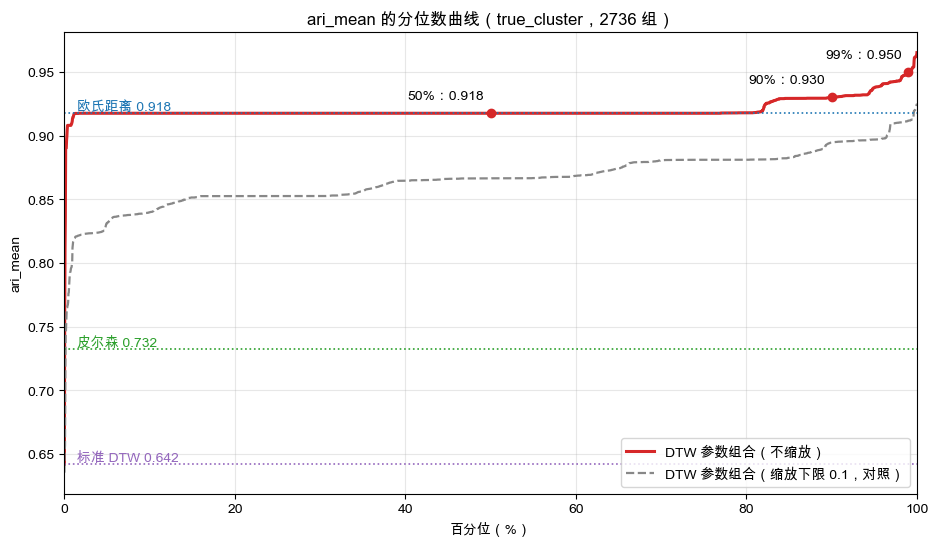

百分位      25%      50%      75%      90%      95%      99%     100%
不缩放    0.918    0.918    0.918    0.930    0.938    0.950    0.965
下限0.1   0.853    0.866    0.881    0.895    0.897    0.912    0.924
ari_mean ≥ 0.9：2727 组（下限 0.1：97 组）
ari_mean ≥ 0.92：494 组（下限 0.1：8 组）
ari_mean ≥ 0.94：113 组（下限 0.1：0 组）


In [3]:
def quantile_curve(rows):
    values = sorted(r[METRIC] for r in rows)
    n = len(values)
    percent = [100*i/(n-1) for i in range(n)] if n > 1 else [100.0]
    return percent, values


def value_at(values, q):
    """Value at percentile q (nearest rank on the sorted list)."""
    return values[round(q/100*(len(values)-1))]


fig, ax = plt.subplots(figsize=(11, 6))
x, y = quantile_curve(dtw)
ax.plot(x, y, color='#d62728', lw=2.2, label='DTW 参数组合（不缩放）')
if compare:
    cx, cy = quantile_curve(compare[0])
    ax.plot(cx, cy, color='#888888', lw=1.6, ls='--', label='DTW 参数组合（缩放下限 0.1，对照）')
styles = {'euclidean': ('#1f77b4', '欧氏距离'), 'pearson': ('#2ca02c', '皮尔森'), 'standard DTW': ('#9467bd', '标准 DTW')}
for name, (color, label) in styles.items():
    if name in refs:
        v = refs[name][METRIC]
        ax.axhline(v, color=color, lw=1.2, ls=':')
        ax.text(1, v, f' {label} {v:.3f}', color=color, va='bottom', fontsize=10)
for q in (50, 90, 99):
    v = value_at(y, q)
    ax.plot([q], [v], 'o', color='#d62728')
    ax.annotate(f'{q}%：{v:.3f}', (q, v), textcoords='offset points', xytext=(-60, 10), fontsize=10)
ax.set_xlabel('百分位（%）'); ax.set_ylabel(METRIC); ax.set_xlim(0, 100)
ax.set_title(f'{METRIC} 的分位数曲线（{SCHEME}，{len(dtw)} 组）'); ax.grid(alpha=.3); ax.legend(loc='lower right')
plt.show()

print('百分位   ' + '   '.join(f'{q:>5}%' for q in (25, 50, 75, 90, 95, 99, 100)))
print('不缩放   ' + '   '.join(f'{value_at(y, q):6.3f}' for q in (25, 50, 75, 90, 95, 99, 100)))
if compare:
    print('下限0.1  ' + '   '.join(f'{value_at(cy, q):6.3f}' for q in (25, 50, 75, 90, 95, 99, 100)))
for t in (0.90, 0.92, 0.94):
    print(f'{METRIC} ≥ {t}：{sum(v >= t for v in y)} 组' + (f'（下限 0.1：{sum(v >= t for v in cy)} 组）' if compare else ''))

## 第 2 步：baseline 上的高分组合，在新数据上表现如何

从 `RESULTS`（baseline）里挑出 `METRIC` 超过 `PICK_ABOVE` 的组合，到 `NEW_RESULTS`（新数据，同一个网格）里查它们的成绩。两份结果都已经算好，这里不重新计算。

- 表格：每个挑出的组合在两份数据上的成绩，以及它在新数据全部组合里排第几、处在第几百分位。
- 散点图：横轴 baseline 成绩，纵轴新数据成绩；灰点是全部组合，红点是挑出的组合。点越靠右上，在两份数据上都越好。

In [ ]:
from IPython.display import Markdown, display

new_rows = [r for r in load_results(Path(NEW_RESULTS)) if r['scheme'] == SCHEME]
new_by_key = {r['key']: r for r in new_rows}
new_dtw = sorted((r for r in new_rows if r['method'] == 'dtw'), key=lambda r: -r[METRIC])
new_rank = {r['key']: i for i, r in enumerate(new_dtw, 1)}

picked = sorted((r for r in dtw if r[METRIC] > PICK_ABOVE), key=lambda r: -r[METRIC])
missing = [r for r in picked if r['key'] not in new_by_key]
print(f'baseline 上 {METRIC} > {PICK_ABOVE}：{len(picked)} 组'
      + (f'；其中 {len(missing)} 组在新数据结果里还没有（网格没跑完？）' if missing else ''))

lines = ['| 配置 | 开启参数 | baseline | 新数据 | 新数据 ARI 最差 | 新数据排名 | 新数据百分位 |',
         '| --- | ---: | ---: | ---: | ---: | ---: | ---: |']
for r in sorted(picked, key=lambda r: -new_by_key[r['key']][METRIC] if r['key'] in new_by_key else 1):
    n = new_by_key.get(r['key'])
    if n is None:
        lines.append(f"| {r['name']} | {r['n_params']} | {r[METRIC]:.4f} | 未算 | | | |")
        continue
    rank = new_rank[r['key']]
    lines.append(f"| {r['name']} | {r['n_params']} | {r[METRIC]:.4f} | {n[METRIC]:.4f} | {n['ari_min']:.4f} | "
                 f"{rank} / {len(new_dtw)} | {100*(1-(rank-1)/max(1, len(new_dtw)-1)):.0f}% |")
lines += ['', '参照（新数据）：' + '，'.join(f"{name} {new_by_key[name][METRIC]:.4f}"
                                        for name in ('euclidean', 'pearson') if name in new_by_key)
          + (f"，standard DTW {next(r[METRIC] for r in new_rows if r['name'] == 'standard DTW'):.4f}"
             if any(r['name'] == 'standard DTW' for r in new_rows) else '')]
display(Markdown('\n'.join(lines)))

In [ ]:
both = [(r[METRIC], new_by_key[r['key']][METRIC]) for r in dtw if r['key'] in new_by_key]
sel = [(r[METRIC], new_by_key[r['key']][METRIC]) for r in picked if r['key'] in new_by_key]
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(*zip(*both), s=8, color='#bbbbbb', alpha=.6, label=f'全部 DTW 组合（{len(both)}）')
if sel:
    ax.scatter(*zip(*sel), s=30, color='#d62728', label=f'baseline {METRIC} > {PICK_ABOVE}（{len(sel)}）')
base_refs = {r['name']: r for r in load_results(Path(RESULTS)) if r['scheme'] == SCHEME}
for name, (color, label) in styles.items():
    if name in base_refs and name in {r['name'] for r in new_rows}:
        nv = next(r[METRIC] for r in new_rows if r['name'] == name)
        ax.scatter([base_refs[name][METRIC]], [nv], marker='*', s=200, color=color, edgecolor='black', label=label, zorder=5)
ax.axvline(PICK_ABOVE, color='#d62728', lw=.8, ls=':')
ax.set_xlabel(f'baseline 上的 {METRIC}'); ax.set_ylabel(f'新数据上的 {METRIC}')
ax.set_title(f'两份数据上的成绩对比（{SCHEME}）'); ax.grid(alpha=.3); ax.legend(loc='lower right', fontsize=9)
plt.show()